### intro

Reproducing [Wikipedia’s PCA example](https://en.wikipedia.org/wiki/Principal_component_analysis) of a multivariate Gaussian distribution centered at (1, 3) with a standard deviation of 3 in roughly the (0.866, 0.5) direction and of 1 in the orthogonal direction with NumPy:

<img src="imgs/wiki_pca.webp" width="400">

### libs

%pip install numpy matplotlib

### imports 

In [11]:
import numpy as np 
import matplotlib.pyplot as plt 

### generate data 

In [12]:
n = 3000
rng = np.random.default_rng(2004)
data = rng.standard_normal((n, 2)) # Draw samples from a standard Normal distribution (mean=0, stdev=1)
data[:, 0] *= 3 
rot = np.array([
    [0.866, -0.5],
    [0.5, 0.866]
]) 
data_rot = data @ rot.T
data_rot[:, 0] += 1
data_rot[:, 1] += 3
data_rot.shape

(3000, 2)

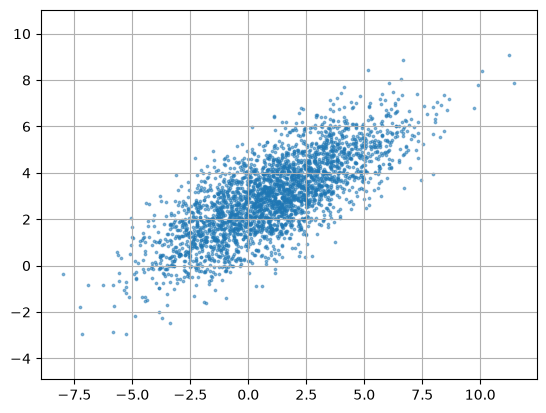

In [13]:
plt.scatter(data_rot[:, 0], data_rot[:, 1], s=3, alpha=0.5)
plt.grid()
plt.axis('equal')
plt.show()

### center data 

In [14]:
data_mean = np.mean(data_rot, axis=0)
data_centred = np.zeros(shape=(n, 2))
data_centred = data_rot - data_mean
data_centred.shape

(3000, 2)

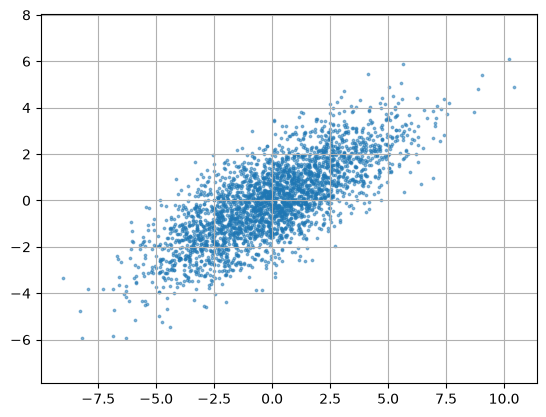

In [15]:
plt.scatter(data_centred[:, 0], data_centred[:, 1], s=3, alpha=0.5)
plt.grid()
plt.axis('equal')
plt.show()

### covariance matrix 

In [18]:
cov_mat = data_centred.T @ data_centred / (n - 1)
cov_mat

array([[6.79993306, 3.35495664],
       [3.35495664, 2.9134024 ]])

### compute eigenvectors/values of the covariance matrix

In [20]:
eigen_mat = np.linalg.eigh(cov_mat)
eigen_mat

EighResult(eigenvalues=array([0.97955357, 8.73378189]), eigenvectors=array([[ 0.49939245, -0.86637589],
       [-0.86637589, -0.49939245]]))

In [21]:
ids = np.argsort(eigen_mat.eigenvalues)[::-1]
values = eigen_mat.eigenvalues[ids]
vectors = eigen_mat.eigenvectors[:, ids]
values, vectors 

(array([8.73378189, 0.97955357]),
 array([[-0.86637589,  0.49939245],
        [-0.49939245, -0.86637589]]))

In [22]:
eigen_mat.eigenvalues / eigen_mat.eigenvalues.sum()

array([0.10084626, 0.89915374])

### dims reduction! 

select top_k features with the biggest eigenvalue

In [32]:
k = 1 
top = vectors[:, :k]
top

array([[-0.86637589],
       [-0.49939245]])

In [33]:
Z = np.dot(data_centred, top)
Z.shape

(3000, 1)

In [34]:
Z.var(ddof=1)

np.float64(8.73378189423177)

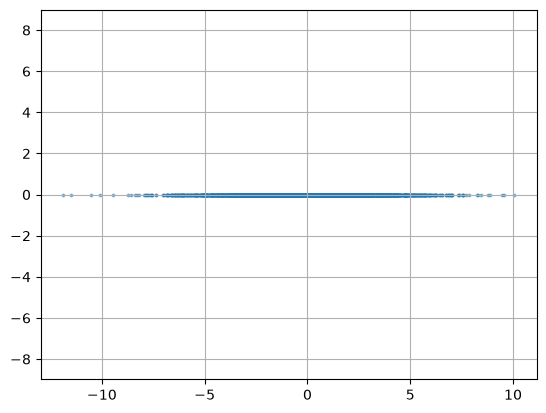

In [35]:
plt.scatter(Z, np.zeros(n), s=3, alpha=0.5)
plt.grid()
plt.axis('equal')
plt.show()

### rank-1 reconstruction

In [41]:
res = (Z @ top.T) + data_mean

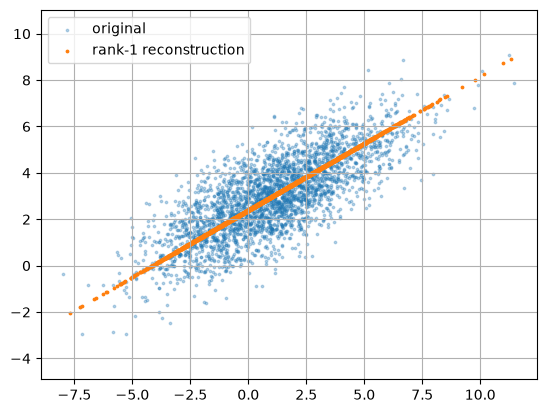

In [42]:
plt.scatter(data_rot[:, 0], data_rot[:, 1], s=3, alpha=0.3, label="original")
plt.scatter(res[:, 0], res[:, 1], s=3, label="rank-1 reconstruction")
plt.grid()
plt.axis('equal')
plt.legend()